# 06 · DreamBooth-LoRA smoke test on a T4 (Phase 2)

**T4 GPU runtime.** About 15–20 min (most of it is downloading SD 1.5, ~4 GB, into `/content` — not Drive).

This notebook:
1. runs a 50-step SD 1.5 DreamBooth-LoRA training with fp16, gradient checkpointing and 8-bit Adam;
2. samples 2 images;
3. records time and VRAM.

The input image is a placeholder (the balloons example). The real images come in Phase 8.

In [1]:
# ==== SETTINGS (edit once) ====================================================================
CODE_SOURCE   = "github"                                      # "github" or "drive"
GITHUB_REPO   = "https://github.com/rishabh-vr/CS787-Single-Image-Diffusion-Editor.git"
GITHUB_BRANCH = "main"
REPO_SUBDIR   = ""                                            # project files are at the repo root
DRIVE_CODE    = "/content/drive/MyDrive/CS787/code/Project"   # used when CODE_SOURCE == "drive"
DRIVE_ROOT    = "/content/drive/MyDrive/CS787"                # outputs, checkpoints, tables, env logs
SID_COMMIT    = "85381e3c6f29fc07144da854d86be07150404716"     # official code, audited commit
SINDDM_COMMIT = "e7107d9fd198928f26e278f99ec428e261726a45"  # SinDDM, audited commit
# If the GitHub repo is private: add a Colab secret named GH_TOKEN (key icon in the left bar)
# holding a fine-grained, read-only token for that repo.

NOTEBOOK = "06_lora_smoke"

In [2]:
import torch, subprocess
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > T4 GPU (then rerun)."
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv"],
                     capture_output=True, text=True).stdout)
print("torch", torch.__version__, "| CUDA", torch.version.cuda,
      "| bf16 native:", torch.cuda.get_device_capability(0) >= (8, 0))

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07

torch 2.14.1+cu130 | CUDA 13.0 | bf16 native: False


In [3]:
import os, shutil, subprocess, sys
from google.colab import drive
drive.mount("/content/drive")
for sub in ("outputs", "checkpoints", "tables", "env_logs", "data"):
    os.makedirs(f"{DRIVE_ROOT}/{sub}", exist_ok=True)

PROJECT = "/content/project"
if os.path.exists(PROJECT):
    shutil.rmtree(PROJECT)
if CODE_SOURCE == "github":
    url = GITHUB_REPO
    try:
        from google.colab import userdata
        token = userdata.get("GH_TOKEN")
        url = GITHUB_REPO.replace("https://", f"https://x-access-token:{token}@")
    except Exception:
        pass  # public repo: no token needed
    subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", GITHUB_BRANCH, url, "/content/repo"], check=True)
    shutil.copytree(os.path.join("/content/repo", REPO_SUBDIR), PROJECT,
                    ignore=shutil.ignore_patterns(".venv", "external", "outputs*"))
else:
    shutil.copytree(DRIVE_CODE, PROJECT, ignore=shutil.ignore_patterns(".venv", "external", "outputs*"))
print("project code at", PROJECT, "->", sorted(os.listdir(PROJECT)))

Mounted at /content/drive
project code at /content/project -> ['.git', '.gitignore', '2606.04299v1.pdf', 'PROJECT_PLAN.md', 'README.md', 'configs', 'docs', 'env', 'notebooks', 'patches', 'pyproject.toml', 'scripts', 'src', 'tests']


In [4]:
DIFFUSERS_VERSION = "0.35.1"
# peft is pinned: the newest peft refuses to load next to Colab's preinstalled torchao 0.10 ("only versions
# above 0.16.0 are supported"). We never use torchao, so it is also removed, which skips that check entirely.
!pip uninstall -q -y torchao
!pip install -q diffusers=={DIFFUSERS_VERSION} transformers==4.53.2 accelerate==1.9.0 peft==0.17.1 bitsandbytes
!wget -q -O /content/train_dreambooth_lora.py https://raw.githubusercontent.com/huggingface/diffusers/v{DIFFUSERS_VERSION}/examples/dreambooth/train_dreambooth_lora.py
!accelerate config default
os.makedirs("/content/lora_inst", exist_ok=True)
!wget -q -O /content/lora_inst/img.png https://raw.githubusercontent.com/haojunqiu/efficient-SID-code/{SID_COMMIT}/examples/uncond/balloons.png

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
accelerate configuration saved at /root/.cache/huggingface/accelerate/default_config.yaml


In [5]:
import time, json, glob, subprocess, torch
cmd = ("accelerate launch /content/train_dreambooth_lora.py "
       "--pretrained_model_name_or_path=stable-diffusion-v1-5/stable-diffusion-v1-5 "
       "--instance_data_dir=/content/lora_inst --instance_prompt='a photo in the style of sks' "
       "--output_dir=/content/lora_out --resolution=512 --train_batch_size=1 --gradient_accumulation_steps=1 "
       "--learning_rate=1e-4 --lr_scheduler=constant --lr_warmup_steps=0 --max_train_steps=50 --rank=8 "
       "--mixed_precision=fp16 --gradient_checkpointing --use_8bit_adam --checkpointing_steps=1000 --seed=0")
t0 = time.time()
ret = subprocess.run(cmd, shell=True).returncode
train_s = time.time() - t0
assert ret == 0 and glob.glob("/content/lora_out/pytorch_lora_weights.*"), \
    "LoRA training FAILED (see the error above) - no weights were written; send the error output"
print(f"50 steps (incl. model download): {train_s:.0f} s")

50 steps (incl. model download): 191 s


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/n

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

{'train_50_steps_s_incl_download': 191.2, 'sample_s_per_image': 5.93, 'sampling_peak_vram_gb': 2.62}


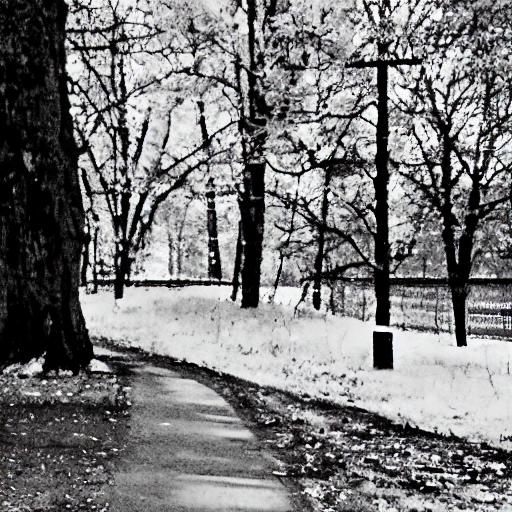

In [6]:
from diffusers import StableDiffusionPipeline
torch.cuda.reset_peak_memory_stats()
pipe = StableDiffusionPipeline.from_pretrained("stable-diffusion-v1-5/stable-diffusion-v1-5",
                                               torch_dtype=torch.float16, safety_checker=None).to("cuda")
pipe.load_lora_weights("/content/lora_out")
t0 = time.time()
imgs = [pipe("a photo in the style of sks", num_inference_steps=30, guidance_scale=7.5,
             generator=torch.Generator("cuda").manual_seed(s)).images[0] for s in (0, 1)]
sample_s = (time.time() - t0) / 2
res = {"train_50_steps_s_incl_download": round(train_s, 1), "sample_s_per_image": round(sample_s, 2),
       "sampling_peak_vram_gb": round(torch.cuda.max_memory_allocated() / 1024**3, 2)}
print(res); json.dump(res, open(f"{DRIVE_ROOT}/tables/phase2_lora_timing.json", "w"), indent=2)
display(imgs[0])

In [7]:
import datetime
stamp = datetime.datetime.now().strftime("%Y-%m-%d_%H%M")
!pip freeze > {DRIVE_ROOT}/env_logs/{stamp}_{NOTEBOOK}_freeze.txt
print("saved", f"{DRIVE_ROOT}/env_logs/{stamp}_{NOTEBOOK}_freeze.txt")

saved /content/drive/MyDrive/CS787/env_logs/2026-11-13_1455_06_lora_smoke_freeze.txt
